In [1]:
!git clone --quiet --depth 1 --branch rev1 https://github.com/huboqiang/omnialigner.git omnialigner-rev1
!wget -q -c -O rev1-fig5-crc-data.tar.gz https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-fig5-crc-data.tar.gz
!pip install -q numpy==1.26.0 scipy==1.15.3 pandas==2.1.1 matplotlib==3.9.1 seaborn==0.13.2

# Original Fig. 5A–B: CRC prediction benchmark

Recalculate the original four-method cell and pseudo-spot marker correlations from frozen predictions for H&E section **WD-76845-096**, paired with measured CyCIF section **WD-76845-097**. All formulas and aggregation steps are visible below. Use Python 3.10/3.11, `git`, `wget`, about 3 GB available RAM and 3 GB disk.

This is the original same-block benchmark, not the later revision's protein-region comparison or an independent-patient validation. The original label “GigaTME” refers here to **GigaTIME**. Available mapped markers differ: GigaTIME **9**, HEX **17**, SpatialEx **24**, OmniPred **24**. Their original boxplots therefore do not represent a comparison on a fixed common marker panel.

**Corrected marker labels:** the original code attached GigaTIME/HEX scores to `list(set(...))` gene names, which discarded column order. Here each score stays with its matrix column's ordered `gene_CRC3d` mapping. Method-level distributions are unchanged; the historical unordered per-marker labels are not treated as valid.

In [2]:
from pathlib import Path
import hashlib,json,sys,tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import KDTree
from scipy.stats import pearsonr
from IPython.display import display

assert (3,10) <= sys.version_info[:2] < (3,12), "Use Python 3.10 or 3.11."
def sha256(path):
    digest=hashlib.sha256()
    with open(path,"rb") as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b""):
            digest.update(block)
    return digest.hexdigest()
archive=Path("rev1-fig5-crc-data.tar.gz")
assert sha256(archive)=="3e8464fad986d2717a24aaa0e1ee058c917a5966caee15fbc13ddd7be80d3368", "Unexpected data archive"
destination=Path("fig5_crc_data").resolve();destination.mkdir(exist_ok=True)
with tarfile.open(archive,"r:gz") as bundle:
    for member in bundle.getmembers():
        assert (destination/member.name).resolve().is_relative_to(destination)
        assert not member.issym() and not member.islnk()
    bundle.extractall(destination)
DATA=destination/"fig5_crc"
OUTPUT=Path("fig5_crc_results");OUTPUT.mkdir(exist_ok=True)
manifest=json.loads((DATA/"manifest.json").read_text())
for name,entry in manifest.items():
    assert sha256(DATA/name)==entry["sha256"],name
with np.load(DATA/"original_inputs.npz",allow_pickle=False) as stored:
    inputs={name:stored[name] for name in stored.files}
audit=json.loads((DATA/"provenance.json").read_text())
print("All input checksums passed.")

All input checksums passed.


## 1. Restore the original preprocessing and marker order

The measured matrix is converted to float64 and transformed with `log1p`. The archived OmniPred prediction is sparse at source and follows `log1p(10*X)`; SpatialEx follows `log1p(X)`. Native GigaTIME/HEX outputs are used as stored. These are processed assay values, not raw RNA counts.

All four stored cell-ID arrays match the measured cohort, and the native baseline coordinates match the annotation coordinates. OmniPred/SpatialEx receive the same annotation coordinates in the original analysis. No cells are chosen based on their prediction score.

In [3]:
METHODS=["GigaTIME","HEX","SpatialEx","OmniPred"]
genes=inputs["gene_names"]
cell_ids=inputs["cell_ids"]
coordinates=inputs["coordinates"][:,:2]
assert len(cell_ids)==563315 and len(genes)==24
assert len(np.unique(cell_ids))==len(cell_ids)
truth=np.log1p(inputs["truth_input"].astype(np.float64))
predictions={
    "OmniPred":np.log1p(10*inputs["OmniPred_input"]),
    "SpatialEx":np.log1p(inputs["SpatialEx_input"]),
    "GigaTIME":inputs["GigaTIME_input"],
    "HEX":inputs["HEX_input"],
}
marker_names={method:inputs[method+"_gene_names"] for method in METHODS}
measured={}
for method in METHODS:
    assert np.array_equal(inputs[method+"_source_cell_ids"],cell_ids)
    indices=pd.Index(genes).get_indexer(marker_names[method])
    assert np.all(indices>=0) and len(np.unique(indices))==len(indices)
    measured[method]=truth[:,indices]
    assert measured[method].shape==predictions[method].shape
    assert np.isfinite(measured[method]).all() and np.isfinite(predictions[method]).all()
coverage=pd.DataFrame({"method":METHODS,"cells":[len(cell_ids)]*4,
                       "mapped_markers":[len(marker_names[m]) for m in METHODS]})
display(coverage)
coverage.to_csv(OUTPUT/"marker_coverage.csv",index=False)

,method,cells,mapped_markers
0,GigaTIME,563315,9
1,HEX,563315,17
2,SpatialEx,563315,24
3,OmniPred,563315,24


## 2. Calculate correlations across cells

For each marker, Pearson correlation compares measured and predicted values across cells:

$$r=\sum_i\frac{y_i-\bar y}{\|y-\bar y\|}\frac{\hat y_i-\bar{\hat y}}{\|\hat y-\bar{\hat y}\|}.$$

The implementation retains the source's numeric type promotion and operation order. Norm scaling avoids overflow and does not change the mathematical correlation. A constant marker remains `NaN`.

In [4]:
def marker_pcc(measured,predicted):
    dtype=np.result_type(measured.dtype,predicted.dtype)
    measured=np.asarray(measured,dtype=dtype)
    predicted=np.asarray(predicted,dtype=dtype)
    x=measured-measured.mean(axis=0,keepdims=True)
    y=predicted-predicted.mean(axis=0,keepdims=True)
    xmax=np.max(np.abs(x),axis=0,keepdims=True)
    ymax=np.max(np.abs(y),axis=0,keepdims=True)
    with np.errstate(divide="ignore",invalid="ignore"):
        xnorm=xmax*np.linalg.norm(x/xmax,axis=0,keepdims=True)
        ynorm=ymax*np.linalg.norm(y/ymax,axis=0,keepdims=True)
        correlations=np.sum(x/xnorm*y/ynorm,axis=0)
    correlations=np.clip(correlations,-1,1)
    constant=np.all(measured==measured[:1],axis=0)|np.all(predicted==predicted[:1],axis=0)
    correlations[constant]=np.nan
    return correlations

records=[]
for method in METHODS:
    values=marker_pcc(measured[method],predictions[method])
    np.testing.assert_allclose(values,pearsonr(measured[method],predictions[method],axis=0).statistic,
                               atol=1e-12,rtol=0,equal_nan=True)
    records.extend(dict(method=method,support="cells",gene=gene,PCC=float(value))
                   for gene,value in zip(marker_names[method],values))
display(pd.DataFrame(records).head(10))

,method,support,gene,PCC
0,GigaTIME,cells,PD1,-0.030672
1,GigaTIME,cells,CD4,0.112024
2,GigaTIME,cells,CD68,-0.013022
3,GigaTIME,cells,CD20,0.056245
4,GigaTIME,cells,CD3,0.005424
5,GigaTIME,cells,CD8a,-0.068139
6,GigaTIME,cells,PDL1,0.158814
7,GigaTIME,cells,Keratin,0.494538
8,GigaTIME,cells,Ki67,0.195345
9,HEX,cells,CD8a,0.080889


## 3. Build the original pseudo-spots explicitly

The historical grid uses X spacing **15**, Y spacing **15√3**, and a second grid starting at X=**50**, Y=**15√3/2**. We retain these exact settings, including the unusual fixed X offset, rather than silently replacing them with a different lattice. A cell joins its nearest grid center if its distance is below **27.5**; retain centers with at least **25 cells**. These are archived coordinate units, not verified micrometres.

Each pseudo-spot is the arithmetic mean of the **already processed** expression values of its member cells. The same cell memberships are used for all methods. Correlation is then calculated across pseudo-spots, separately for each available marker.

In [5]:
def original_spot_membership(xy,x_interval=15,min_cells=25):
    y_interval=x_interval*np.sqrt(3)
    x1,y1=np.meshgrid(np.arange(0,xy[:,0].max()+x_interval,x_interval),
                      np.arange(0,xy[:,1].max()+y_interval,y_interval))
    x2,y2=np.meshgrid(np.arange(50,xy[:,0].max()+x_interval,x_interval),
                      np.arange(y_interval/2,xy[:,1].max()+y_interval,y_interval))
    centers=np.vstack([np.column_stack([x1.ravel(),y1.ravel()]),
                       np.column_stack([x2.ravel(),y2.ravel()])])
    distance,nearest=KDTree(centers).query(xy)
    nearest[distance>=27.5]=-1
    counts=np.bincount(nearest[nearest>=0],minlength=len(centers))
    valid_spots=np.flatnonzero(counts>=min_cells)
    included=np.isin(nearest,valid_spots)
    return nearest,valid_spots,included,centers[valid_spots]

spot_id,valid_spots,included,centers=original_spot_membership(coordinates)
assert len(valid_spots)==1684 and int(included.sum())==561994
print(len(valid_spots),"pseudo-spots;",int(included.sum()),"/",len(cell_ids),"cells retained")

def mean_by_spot(values,names,spot_id,included):
    table=pd.DataFrame(values[included],columns=names)
    table["spot_id"]=spot_id[included]
    grouped=table.groupby("spot_id",sort=True).mean()
    # The source appends integer old_id/id columns before taking .values,
    # promoting the resulting numerical matrix to float64; preserve that behavior.
    return grouped.index.to_numpy(),grouped.to_numpy().astype(np.float64)

expected_aggregation=np.load(DATA/"expected_aggregation.npz",allow_pickle=False)
assert np.array_equal(included,expected_aggregation["in_valid_spot"])
np.testing.assert_array_equal(centers,expected_aggregation["spot_centers"])
spot_measured={};spot_predicted={};aggregation_max_abs_difference={}
for method in METHODS:
    gt_ids,spot_measured[method]=mean_by_spot(measured[method],marker_names[method],spot_id,included)
    pred_ids,spot_predicted[method]=mean_by_spot(predictions[method],marker_names[method],spot_id,included)
    np.testing.assert_array_equal(gt_ids,pred_ids)
    np.testing.assert_array_equal(gt_ids,expected_aggregation[method+"_old_spot_ids"])
    np.testing.assert_allclose(spot_measured[method],expected_aggregation[method+"_truth"],atol=1e-12,rtol=0)
    # Float32 log1p/aggregation can differ by a few ULPs across CPU platforms.
    aggregation_max_abs_difference[method]=float(np.max(np.abs(
        spot_predicted[method]-expected_aggregation[method+"_predicted"])))
    np.testing.assert_allclose(spot_predicted[method],expected_aggregation[method+"_predicted"],
                               atol=1e-12,rtol=3e-7)
    values=marker_pcc(spot_measured[method],spot_predicted[method])
    records.extend(dict(method=method,support="pseudo-spots",gene=gene,PCC=float(value))
                   for gene,value in zip(marker_names[method],values))
scores=pd.DataFrame(records)
scores.to_csv(OUTPUT/"Fig5_marker_pcc.csv",index=False)

1684 pseudo-spots; 561994 / 563315 cells retained


## 4. Verify the recovered source and its cached outputs

Compare every marker/support score and every aggregated value with the recovered source calculation. Also check the original notebook's cached pseudo-spot means, **0.7905389511977857** for OmniPred and **0.6845747704032076** for SpatialEx. These historical cache values are independent of this new export.

Checks use a PCC absolute tolerance of **1e-7** and prediction-aggregate relative tolerance of **3e-7**, allowing float32 platform differences while preserving the original calculations. The Linux source replay differed by at most 3.3e-15 in PCC; macOS ARM testing differed by at most 2.9e-8 in PCC and 4.8e-7 in an aggregate value. Cell memberships and spot identities must match exactly; tolerances do not change the reported scores.

In [6]:
expected=pd.read_csv(DATA/"expected_gene_pcc.csv")
check=scores.merge(expected,on=["method","support","gene"],validate="one_to_one",suffixes=("","_expected"))
assert len(check)==2*(9+17+24+24)==148
np.testing.assert_allclose(check.PCC,check.PCC_expected,atol=1e-7,rtol=0,equal_nan=True)
summary=scores.groupby(["support","method"]).PCC.agg(n_markers="count",mean="mean",median="median").reset_index()
for method,cached in audit["historical_cached_spot_means"].items():
    current=summary.loc[(summary.method==method)&(summary.support=="pseudo-spots"),"mean"].iloc[0]
    np.testing.assert_allclose(current,cached,atol=1e-7,rtol=0)
validation={"status":"passed","scores_checked":len(check),"cells":len(cell_ids),
            "pseudo_spots":len(valid_spots),"cells_in_valid_spots":int(included.sum()),
            "max_abs_pcc_difference":float(np.nanmax(np.abs(check.PCC-check.PCC_expected))),
            "historical_cached_means_verified":True,"ordered_marker_mapping":True,
            "pcc_absolute_tolerance":1e-7,"aggregation_relative_tolerance":3e-7,
            "aggregation_max_abs_difference":aggregation_max_abs_difference}
(OUTPUT/"validation.json").write_text(json.dumps(validation,indent=2))
summary.to_csv(OUTPUT/"Fig5_summary.csv",index=False)
display(summary)
display(pd.DataFrame([validation]))

,support,method,n_markers,mean,median
0,cells,GigaTIME,9,0.101173,0.056245
1,cells,HEX,17,0.137430,0.171042
2,cells,OmniPred,24,0.500700,0.516288
3,cells,SpatialEx,24,0.273994,0.252736
4,pseudo-spots,GigaTIME,9,0.130195,-0.116523
5,pseudo-spots,HEX,17,0.250207,0.320082
6,pseudo-spots,OmniPred,24,0.790539,0.856829
7,pseudo-spots,SpatialEx,24,0.684575,0.724423


,status,scores_checked,cells,pseudo_spots,cells_in_valid_spots,max_abs_pcc_difference,historical_cached_means_verified,ordered_marker_mapping,pcc_absolute_tolerance,aggregation_relative_tolerance,aggregation_max_abs_difference
0,passed,148,563315,1684,561994,2.865812e-08,True,True,1.000000e-07,3.000000e-07,"{'GigaTIME': 0.0, 'HEX': 0.0, 'SpatialEx': 4.7..."


## 5. Draw the original comparison with explicit units and corrected labels

The first figure reproduces the method-level distributions. The second displays per-marker pseudo-spot correlations using the verified ordered labels; a missing method/marker combination is left absent. It is a corrected marker-label view, not certification of the historical unordered marker plot.

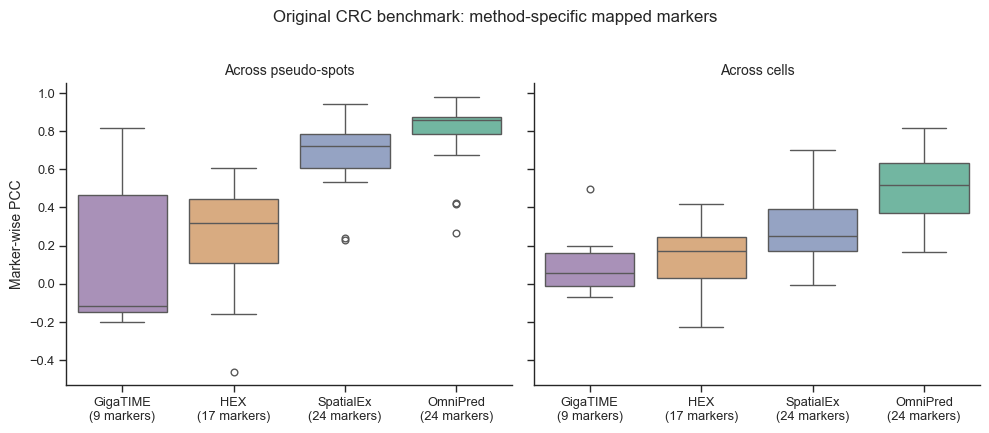

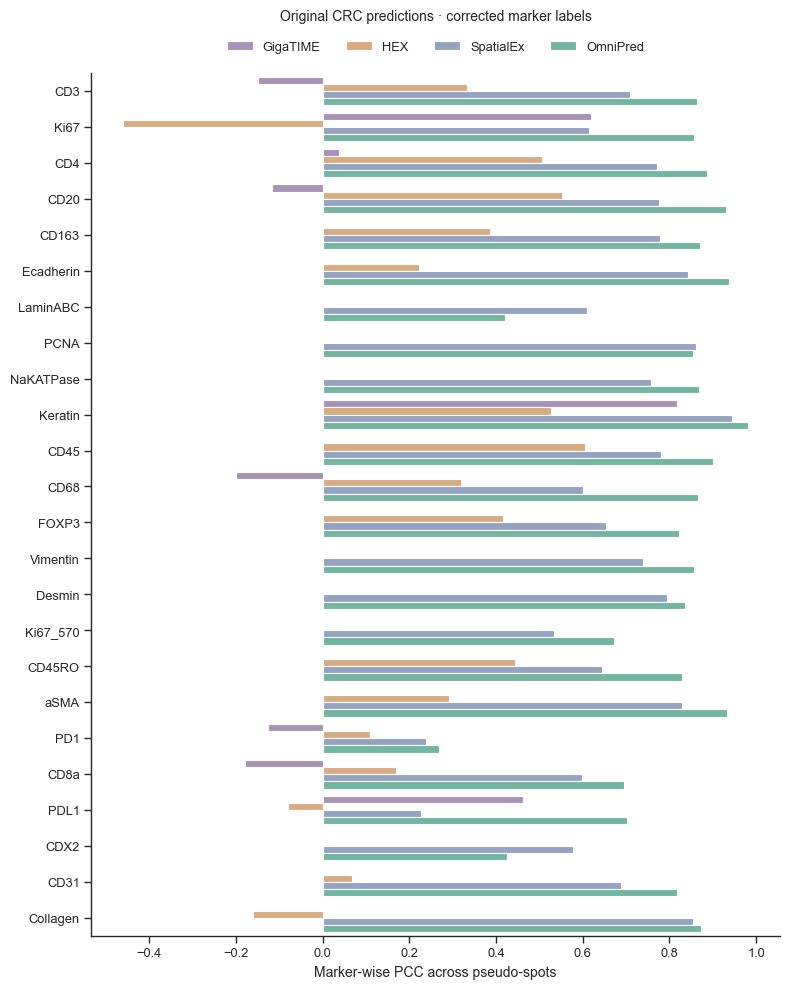

In [7]:
sns.set_theme(style="ticks",context="paper",font_scale=1.05)
palette={"GigaTIME":"#aa8abf","HEX":"#e6ab72","SpatialEx":"#8da0cb","OmniPred":"#66c2a5"}
fig,axes=plt.subplots(1,2,figsize=(10,4.2),sharey=True)
for ax,support,title in zip(axes,["pseudo-spots","cells"],["Across pseudo-spots","Across cells"]):
    subset=scores[scores.support==support]
    sns.boxplot(data=subset,x="method",y="PCC",order=METHODS,hue="method",hue_order=METHODS,
                palette=palette,legend=False,dodge=False,ax=ax)
    ax.set_title(title);ax.set_xlabel("");ax.set_ylabel("Marker-wise PCC")
    ax.set_xticks(range(4),[f"{m}\n({len(marker_names[m])} markers)" for m in METHODS])
    sns.despine(ax=ax)
fig.suptitle("Original CRC benchmark: method-specific mapped markers",y=1.02)
fig.tight_layout()
fig.savefig(OUTPUT/"Fig5A_original_benchmark.pdf",bbox_inches="tight")
fig.savefig(OUTPUT/"Fig5A_original_benchmark.png",dpi=180,bbox_inches="tight")
plt.show()

fig,ax=plt.subplots(figsize=(8,10))
sns.barplot(data=scores[scores.support=="pseudo-spots"],y="gene",x="PCC",hue="method",
            order=genes.tolist(),hue_order=METHODS,palette=palette,errorbar=None,ax=ax)
ax.set_xlabel("Marker-wise PCC across pseudo-spots");ax.set_ylabel("")
ax.set_title("Original CRC predictions · corrected marker labels",pad=38)
ax.legend(title=None,loc="lower center",bbox_to_anchor=(0.5,1.01),ncol=4,frameon=False)
sns.despine(ax=ax);fig.tight_layout()
fig.savefig(OUTPUT/"Fig5B_corrected_marker_labels.pdf",bbox_inches="tight")
fig.savefig(OUTPUT/"Fig5B_corrected_marker_labels.png",dpi=180,bbox_inches="tight")
plt.show()

## Provenance and limits

The recovered `imputation_3d.ipynb` source, zero-based cells 1 and 17–25, is archived in `original_source_cells.json`; its complete notebook SHA-256 is `74d320906d9f6d9fd2b63baf37788f390ac97e9129867400980907a04cc5ee69`. Input hashes and original source paths are recorded in `provenance.json`, solely as provenance. Execution never reads those private paths.

The original cell-level panel means marker-wise correlation across cells, not a within-cell expression-profile correlation. Pseudo-spot aggregation changes the spatial support and must not be called cell-level accuracy. This notebook scores saved predictions; it does not retrain models, independently validate pathology, or replace the later revision benchmark. The original notebook selects the `spatranslator_v5_celltypes_train5` prediction directory; inference from a newly loaded checkpoint is a separate task.